# UTS Graf Sains Data

**Nama:** Shakyla Andhara Chandraningtyas

**NIM:** 24031554199

**Mata Kuliah:** Graf Sains Data
## Data Preparation

Analisis ini menggunakan dataset RetailRocket untuk membangun graf interaksi antara pengunjung dan barang. Periode data dibagi menjadi periode training (P1) dan testing (P2).

- **Periode Training (P1):** 3 Mei 2015 – 5 Juni 2015
- **Periode Testing (P2):** 6 Juni 2015 – 14 Juni 2015

## **Impor library**

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from pathlib import Path
import pandas as pd
from pathlib import Path

## **Baca dataset**

In [88]:
DATA_PATH = Path("../data/events.csv")

print("Lokasi dataset:", DATA_PATH.resolve())
print("File ditemukan:", DATA_PATH.exists())

Lokasi dataset: C:\Users\lenovo loq\Downloads\UTS_Graf_Sains_Data\data\events.csv
File ditemukan: True


In [90]:
df = pd.read_csv(DATA_PATH)

print("Ukuran dataset:", df.shape)
print("\nNama kolom:")
print(df.columns.tolist())

print("\nLima baris pertama:")
display(df.head())

Ukuran dataset: (2756101, 5)

Nama kolom:
['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']

Lima baris pertama:


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


## **Mengubah timestamp menjadi tanggal**

In [91]:
df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms")

print("Tanggal paling awal:", df["datetime"].min())
print("Tanggal paling akhir:", df["datetime"].max())

display(df[["timestamp", "datetime", "visitorid", "event", "itemid"]].head())

Tanggal paling awal: 2015-05-03 03:00:04.384000
Tanggal paling akhir: 2015-09-18 02:59:47.788000


,timestamp,datetime,visitorid,event,itemid
0,1433221332117,2015-06-02 05:02:12.117,257597,view,355908
1,1433224214164,2015-06-02 05:50:14.164,992329,view,248676
2,1433221999827,2015-06-02 05:13:19.827,111016,view,318965
3,1433221955914,2015-06-02 05:12:35.914,483717,view,253185
4,1433221337106,2015-06-02 05:02:17.106,951259,view,367447


## **Memisahkan data berdasarkan P1 dan P2**

In [92]:
P1_START = pd.Timestamp("2015-05-03 00:00:00")
P1_END   = pd.Timestamp("2015-06-06 00:00:00")

P2_START = pd.Timestamp("2015-06-06 00:00:00")
P2_END   = pd.Timestamp("2015-06-15 00:00:00")

df_p1 = df[
    (df["datetime"] >= P1_START) &
    (df["datetime"] < P1_END)
].copy()

df_p2 = df[
    (df["datetime"] >= P2_START) &
    (df["datetime"] < P2_END)
].copy()

print("Jumlah data P1 (training):", len(df_p1))
print("Jumlah data P2 (testing):", len(df_p2))

print("\nRentang waktu P1:")
print(df_p1["datetime"].min(), "sampai", df_p1["datetime"].max())

print("\nRentang waktu P2:")
print(df_p2["datetime"].min(), "sampai", df_p2["datetime"].max())

Jumlah data P1 (training): 704786
Jumlah data P2 (testing): 164163

Rentang waktu P1:
2015-05-03 03:00:04.384000 sampai 2015-06-05 23:59:53.628000

Rentang waktu P2:
2015-06-06 00:00:00.445000 sampai 2015-06-14 23:59:53.633000


## **Simpan data P1 dan P2 ke file CSV**

In [9]:
df_p1.to_csv("../data/events_P1_training.csv", index=False)
df_p2.to_csv("../data/events_P2_testing.csv", index=False)

print("Data P1 berhasil disimpan:", len(df_p1), "baris")
print("Data P2 berhasil disimpan:", len(df_p2), "baris")

Data P1 berhasil disimpan: 704786 baris
Data P2 berhasil disimpan: 164163 baris


In [10]:
print("Komposisi event P1 (training):")
display(df_p1["event"].value_counts().to_frame("jumlah"))

print("\nKomposisi event P2 (testing):")
display(df_p2["event"].value_counts().to_frame("jumlah"))

Komposisi event P1 (training):


,jumlah
event,
view,682160
addtocart,17051
transaction,5575



Komposisi event P2 (testing):


,jumlah
event,
view,159183
addtocart,3804
transaction,1176


## **Koneksi Python ke Neo4j**

In [3]:
from neo4j import GraphDatabase

NEO4J_URI = "neo4j://127.0.0.1:7687"
NEO4J_USER = "neo4j"
NEO4J_PASSWORD = "shakylaac"

driver = GraphDatabase.driver(
    NEO4J_URI,
    auth=(NEO4J_USER, NEO4J_PASSWORD)
)

print("Objek koneksi Neo4j berhasil dibuat.")

Objek koneksi Neo4j berhasil dibuat.


In [4]:
driver.verify_connectivity()
print("Koneksi ke Neo4j berhasil!")

Koneksi ke Neo4j berhasil!


C:\Users\lenovo loq\AppData\Local\Temp\ipykernel_16680\2375010610.py:1: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


In [5]:
with driver.session(database="neo4j") as session:
    result = session.run("""
        MATCH (n)
        RETURN count(n) AS jumlah_node
    """)

    record = result.single()
    print("Jumlah node saat ini:", record["jumlah_node"])

Jumlah node saat ini: 0


In [11]:
print("Ukuran data P1:", pd.read_csv(P1_PATH).shape)
print("Ukuran data P2:", pd.read_csv(P2_PATH).shape)

Ukuran data P1: (704786, 6)
Ukuran data P2: (164163, 6)


In [10]:
df_p1 = pd.read_csv(P1_PATH)

display(df_p1.head())
print("Nama kolom:", df_p1.columns.tolist())
print("Jumlah baris:", len(df_p1))
print("Jumlah pengunjung unik:", df_p1["visitorid"].nunique())
print("Jumlah barang unik:", df_p1["itemid"].nunique())

,timestamp,visitorid,event,itemid,transactionid,datetime
0,1433221332117,257597,view,355908,NaN,2015-06-02 05:02:12.117
1,1433224214164,992329,view,248676,NaN,2015-06-02 05:50:14.164
2,1433221999827,111016,view,318965,NaN,2015-06-02 05:13:19.827
3,1433221955914,483717,view,253185,NaN,2015-06-02 05:12:35.914
4,1433221337106,951259,view,367447,NaN,2015-06-02 05:02:17.106


Nama kolom: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid', 'datetime']
Jumlah baris: 704786
Jumlah pengunjung unik: 363786
Jumlah barang unik: 125585


## **Menyiapkan query untuk memasukkan data P1**

In [14]:
from tqdm.notebook import tqdm

df_p1 = pd.read_csv(P1_PATH)

df_p1["visitorid"] = df_p1["visitorid"].astype("int64")
df_p1["itemid"] = df_p1["itemid"].astype("int64")
df_p1["timestamp"] = df_p1["timestamp"].astype("int64")

df_p1["transactionid"] = df_p1["transactionid"].where(
    df_p1["transactionid"].notna(), None
)

print("Data P1 siap diimpor:", len(df_p1), "baris")

Data P1 siap diimpor: 704786 baris


## **Impor data P1 ke Neo4j**

In [32]:
with driver.session(database="neo4j") as session:
    session.run("""
        CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS
        FOR (v:Visitor)
        REQUIRE v.id IS UNIQUE
    """).consume()

    session.run("""
        CREATE CONSTRAINT item_id_unique IF NOT EXISTS
        FOR (i:Item)
        REQUIRE i.id IS UNIQUE
    """).consume()

print("Constraint Visitor dan Item berhasil dibuat.")

Constraint Visitor dan Item berhasil dibuat.


In [35]:
from tqdm.notebook import tqdm

BATCH_SIZE = 20000

cypher_visitor = """
UNWIND $ids AS visitor_id
MERGE (:Visitor {id: visitor_id})
"""

with driver.session(database="neo4j") as session:
    for start in tqdm(range(0, len(visitor_ids), BATCH_SIZE)):
        batch = visitor_ids[start:start + BATCH_SIZE]

        session.run(
            cypher_visitor,
            ids=[int(visitor_id) for visitor_id in batch]
        ).consume()

print("Semua node Visitor berhasil dipastikan tersedia!")

  0%|          | 0/19 [00:00<?, ?it/s]

Semua node Visitor berhasil dipastikan tersedia!


In [36]:
with driver.session(database="neo4j") as session:
    result = session.run("""
        MATCH (v:Visitor)
        RETURN count(v) AS jumlah_visitor
    """)
    print("Jumlah node Visitor:", result.single()["jumlah_visitor"])

Jumlah node Visitor: 363786


In [37]:
item_ids = df_p1["itemid"].dropna().unique().tolist()

print("Jumlah Item unik:", len(item_ids))

Jumlah Item unik: 125585


In [38]:
from tqdm.notebook import tqdm

BATCH_SIZE = 20000

cypher_item = """
UNWIND $ids AS item_id
MERGE (:Item {id: item_id})
"""

with driver.session(database="neo4j") as session:
    for start in tqdm(range(0, len(item_ids), BATCH_SIZE)):
        batch = item_ids[start:start + BATCH_SIZE]

        session.run(
            cypher_item,
            ids=[int(item_id) for item_id in batch]
        ).consume()

print("Semua node Item berhasil dimasukkan!")

  0%|          | 0/7 [00:00<?, ?it/s]

Semua node Item berhasil dimasukkan!


In [39]:
with driver.session(database="neo4j") as session:
    result = session.run("""
        MATCH (i:Item)
        RETURN count(i) AS jumlah_item
    """)
    print("Jumlah node Item:", result.single()["jumlah_item"])

Jumlah node Item: 125585


In [40]:
from tqdm.notebook import tqdm
import pandas as pd

BATCH_SIZE = 5000

cypher_interaction = """
UNWIND $rows AS row
MATCH (v:Visitor {id: row.visitorid})
MATCH (i:Item {id: row.itemid})
CREATE (v)-[r:INTERACTED {
    event: row.event,
    timestamp: row.timestamp
}]->(i)
SET r.transactionid = row.transactionid
"""

with driver.session(database="neo4j") as session:
    for start in tqdm(range(0, len(df_p1), BATCH_SIZE)):
        batch = df_p1.iloc[start:start + BATCH_SIZE]

        rows = []
        for row in batch[
            ["visitorid", "itemid", "event", "timestamp", "transactionid"]
        ].to_dict("records"):
            rows.append({
                "visitorid": int(row["visitorid"]),
                "itemid": int(row["itemid"]),
                "event": row["event"],
                "timestamp": int(row["timestamp"]),
                "transactionid": (
                    int(row["transactionid"])
                    if pd.notna(row["transactionid"])
                    else None
                )
            })

        session.run(cypher_interaction, rows=rows).consume()

print("Semua relasi INTERACTED berhasil dimasukkan!")

  0%|          | 0/141 [00:00<?, ?it/s]

Semua relasi INTERACTED berhasil dimasukkan!


In [41]:
with driver.session(database="neo4j") as session:
    result = session.run("""
        MATCH ()-[r:INTERACTED]->()
        RETURN count(r) AS jumlah_interaksi
    """)
    print("Jumlah relasi INTERACTED:", result.single()["jumlah_interaksi"])

Jumlah relasi INTERACTED: 704786


In [42]:
with driver.session(database="neo4j") as session:
    result = session.run("""
        MATCH (v:Visitor)
        WITH count(v) AS jumlah_visitor
        MATCH (i:Item)
        WITH jumlah_visitor, count(i) AS jumlah_item
        MATCH ()-[r:INTERACTED]->()
        RETURN
            jumlah_visitor,
            jumlah_item,
            count(r) AS jumlah_interaksi
    """)

    data = result.single()

    print("Jumlah node Visitor :", data["jumlah_visitor"])
    print("Jumlah node Item    :", data["jumlah_item"])
    print("Jumlah relasi       :", data["jumlah_interaksi"])

Jumlah node Visitor : 363786
Jumlah node Item    : 125585
Jumlah relasi       : 704786


Graf yang dibangun merupakan graf bipartit, yaitu graf yang terdiri dari dua kelompok node berbeda, yakni Visitor dan Item. Relasi INTERACTED menghubungkan pengunjung dengan barang yang pernah mereka lihat, tambahkan ke keranjang, atau beli. Setiap baris pada data P1 direpresentasikan sebagai satu relasi, sehingga interaksi berulang antara pengunjung dan barang yang sama tetap dapat tercatat.

In [43]:
with driver.session(database="neo4j") as session:
    result = session.run("""
        MATCH ()-[r:INTERACTED]->()
        RETURN r.event AS jenis_event, count(r) AS jumlah
        ORDER BY jumlah DESC
    """)

    for record in result:
        print(f"{record['jenis_event']}: {record['jumlah']}")

view: 682160
addtocart: 17051
transaction: 5575


Berdasarkan hasil pemrosesan data periode P1, graf yang terbentuk terdiri atas 363.786 node Visitor, 125.585 node Item, dan 704.786 relasi INTERACTED. Graf ini merepresentasikan hubungan antara pengunjung dan barang berdasarkan aktivitas yang tercatat dalam dataset RetailRocket. Relasi dibedakan melalui properti event, yaitu view, addtocart, dan transaction, sehingga pola interaksi pengguna dengan barang dapat dianalisis lebih lanjut.

## **Membuat VSM Visitor–Item**

In [46]:
from scipy.sparse import csr_matrix
visitor_map = {
    visitor_id: idx
    for idx, visitor_id in enumerate(df_p1["visitorid"].dropna().unique())
}

item_map = {
    item_id: idx
    for idx, item_id in enumerate(df_p1["itemid"].dropna().unique())
}

row_indices = df_p1["visitorid"].map(visitor_map).to_numpy()
col_indices = df_p1["itemid"].map(item_map).to_numpy()

values = np.ones(len(df_p1), dtype=np.float32)

visitor_item_matrix = csr_matrix(
    (values, (row_indices, col_indices)),
    shape=(len(visitor_map), len(item_map))
)

print("Shape matriks VSM:", visitor_item_matrix.shape)
print("Jumlah interaksi non-zero:", visitor_item_matrix.nnz)

Shape matriks VSM: (363786, 125585)
Jumlah interaksi non-zero: 546557


## **Normalisasi VSM Visitor**

In [47]:
from sklearn.preprocessing import normalize

visitor_vsm = normalize(visitor_item_matrix, norm="l2", axis=1)

print("Shape Visitor VSM:", visitor_vsm.shape)
print("Jumlah nilai non-zero:", visitor_vsm.nnz)

Shape Visitor VSM: (363786, 125585)
Jumlah nilai non-zero: 546557


In [74]:
import networkx as nx

jumlah_sampel = min(100, len(visitor_map))
visitor_sampel = list(visitor_map.keys())[:jumlah_sampel]

df_sampel = df_p1[
    df_p1["visitorid"].isin(visitor_sampel)
][["visitorid", "itemid"]].drop_duplicates()

G_bipartit_visitor = nx.Graph()

G_bipartit_visitor.add_nodes_from(
    visitor_sampel, bipartite="visitor"
)

G_bipartit_visitor.add_nodes_from(
    df_sampel["itemid"].unique(), bipartite="item"
)

G_bipartit_visitor.add_edges_from(
    df_sampel[["visitorid", "itemid"]].itertuples(
        index=False, name=None
    )
)

G_proyeksi_visitor = nx.bipartite.weighted_projected_graph(
    G_bipartit_visitor,
    visitor_sampel
)

print("Jumlah node proyeksi Visitor:",
      G_proyeksi_visitor.number_of_nodes())
print("Jumlah edge proyeksi Visitor:",
      G_proyeksi_visitor.number_of_edges())

Jumlah node proyeksi Visitor: 100
Jumlah edge proyeksi Visitor: 3


## **Visualisasikan graf**

In [75]:
interaksi_unik = df_p1[["visitorid", "itemid"]].drop_duplicates()

visitor_teraktif = (
    interaksi_unik.groupby("visitorid")["itemid"]
    .count()
    .sort_values(ascending=False)
    .head(100)
    .index
    .tolist()
)

df_sampel_visitor = interaksi_unik[
    interaksi_unik["visitorid"].isin(visitor_teraktif)
]

G_bipartit_visitor = nx.Graph()

G_bipartit_visitor.add_nodes_from(
    visitor_teraktif, bipartite="visitor"
)

G_bipartit_visitor.add_nodes_from(
    df_sampel_visitor["itemid"].unique(), bipartite="item"
)

G_bipartit_visitor.add_edges_from(
    df_sampel_visitor[["visitorid", "itemid"]]
    .itertuples(index=False, name=None)
)

G_proyeksi_visitor = nx.bipartite.weighted_projected_graph(
    G_bipartit_visitor,
    visitor_teraktif
)

print("Jumlah node proyeksi Visitor:",
      G_proyeksi_visitor.number_of_nodes())
print("Jumlah edge proyeksi Visitor:",
      G_proyeksi_visitor.number_of_edges())

Jumlah node proyeksi Visitor: 100
Jumlah edge proyeksi Visitor: 2922


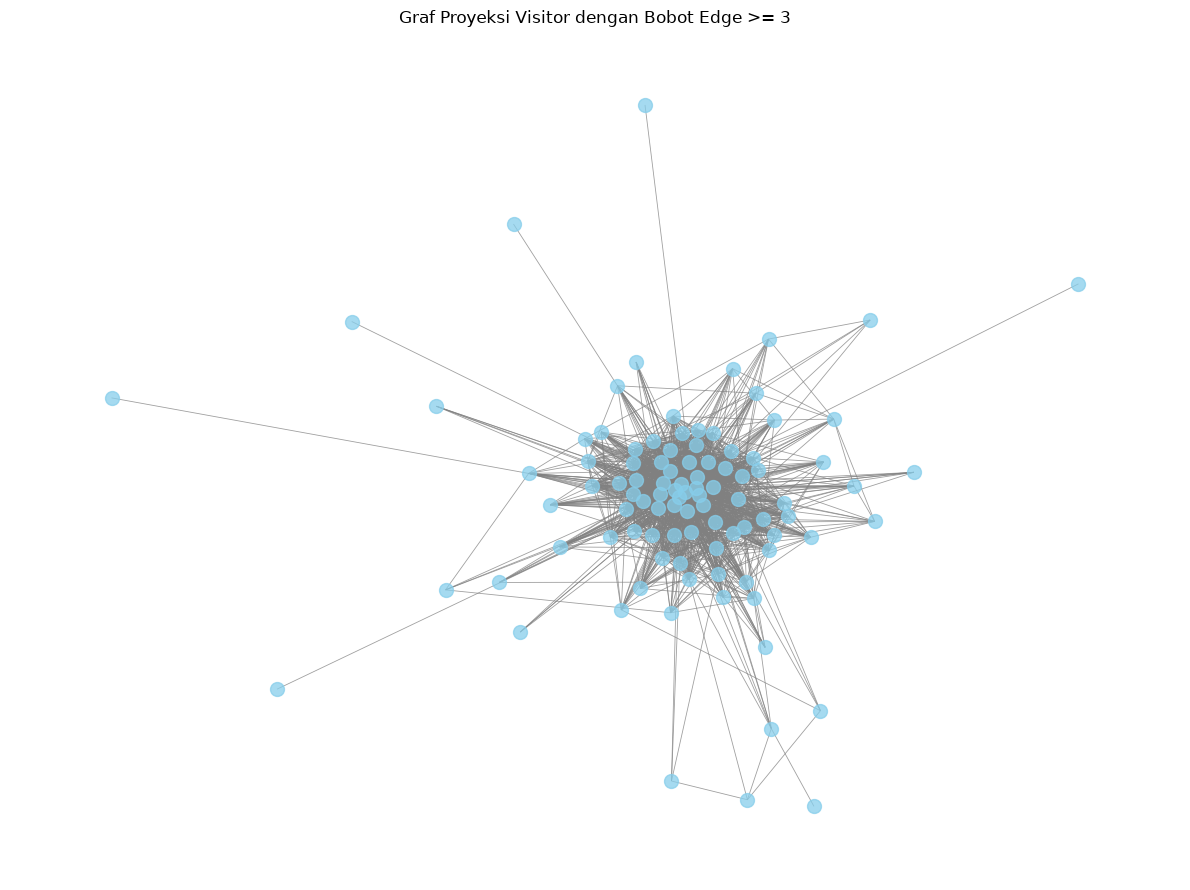

Node setelah filter: 98
Edge setelah filter: 1670


In [77]:
batas_bobot = 3

G_visitor_filter = nx.Graph()
G_visitor_filter.add_nodes_from(G_proyeksi_visitor.nodes())

G_visitor_filter.add_edges_from(
    (u, v, data)
    for u, v, data in G_proyeksi_visitor.edges(data=True)
    if data["weight"] >= batas_bobot
)

G_visitor_filter.remove_nodes_from(
    list(nx.isolates(G_visitor_filter))
)

plt.figure(figsize=(12, 9))

pos_filter = nx.spring_layout(
    G_visitor_filter,
    seed=42,
    weight="weight",
    k=0.5
)

nx.draw_networkx(
    G_visitor_filter,
    pos_filter,
    with_labels=False,
    node_size=100,
    node_color="skyblue",
    edge_color="gray",
    width=0.6,
    alpha=0.75
)

plt.title("Graf Proyeksi Visitor dengan Bobot Edge >= 3")
plt.axis("off")
plt.tight_layout()
plt.show()

print("Node setelah filter:", G_visitor_filter.number_of_nodes())
print("Edge setelah filter:", G_visitor_filter.number_of_edges())

Visualisasi graf proyeksi visitor dengan bobot edge >3 menunjukkan struktur klaster padat di bagian tengah yang merepresentasikan kelompok pengguna dengan preferensi belanja serupa, serta beberapa node di bagian pinggiran yang mencirikan perilaku belanja unik.

## **Membuat VSM Item**

In [48]:
item_visitor_matrix = visitor_item_matrix.T.tocsr()

item_vsm = normalize(item_visitor_matrix, norm="l2", axis=1)

print("Shape Item VSM:", item_vsm.shape)
print("Jumlah nilai non-zero:", item_vsm.nnz)

Shape Item VSM: (125585, 363786)
Jumlah nilai non-zero: 546557


VSM Visitor merepresentasikan setiap pengunjung berdasarkan barang yang berinteraksi dengannya. Sementara itu, VSM Item merepresentasikan setiap barang berdasarkan pengunjung yang berinteraksi dengannya. Kedua matriks dibentuk dari data interaksi yang sama, tetapi orientasi baris dan kolomnya berbeda.

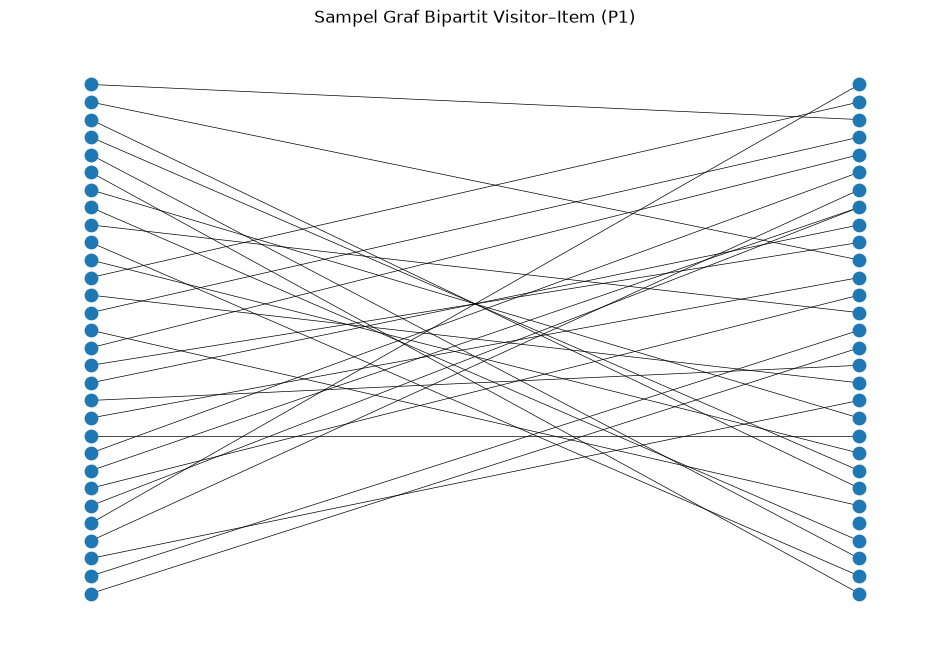

Jumlah node sampel: 60
Jumlah edge sampel: 30


In [52]:
import networkx as nx
import matplotlib.pyplot as plt

sample_visitors = set(df_p1["visitorid"].dropna().unique()[:30])
sample_items = set(df_p1["itemid"].dropna().unique()[:30])

sample_df = df_p1[
    df_p1["visitorid"].isin(sample_visitors)
    & df_p1["itemid"].isin(sample_items)
]

G_sample = nx.Graph()

G_sample.add_nodes_from(
    [(f"V{v}", {"bipartite": 0}) for v in sample_visitors]
)
G_sample.add_nodes_from(
    [(f"I{i}", {"bipartite": 1}) for i in sample_items]
)

G_sample.add_edges_from(
    (f"V{row.visitorid}", f"I{row.itemid}")
    for row in sample_df.itertuples()
)

pos = nx.bipartite_layout(
    G_sample,
    [f"V{v}" for v in sample_visitors]
)

plt.figure(figsize=(12, 8))
nx.draw_networkx(
    G_sample,
    pos=pos,
    with_labels=False,
    node_size=80,
    width=0.5
)
plt.title("Sampel Graf Bipartit Visitor–Item (P1)")
plt.axis("off")
plt.show()

print("Jumlah node sampel:", G_sample.number_of_nodes())
print("Jumlah edge sampel:", G_sample.number_of_edges())

Visualisasi NetworkX menampilkan sampel graf bipartit yang terdiri dari 30 node Visitor, 30 node Item, dan 30 edge yang menghubungkan keduanya. Node Visitor dan Item ditempatkan pada kelompok berbeda untuk memperlihatkan pola hubungan antara pengunjung dan barang. Visualisasi ini membantu memahami struktur graf secara sederhana tanpa harus menampilkan seluruh node dan relasi dari dataset yang berukuran besar.

## **Graf Proyeksi Item**

In [78]:
interaksi_unik = df_p1[["visitorid", "itemid"]].drop_duplicates()

item_terpopuler = (
    interaksi_unik.groupby("itemid")["visitorid"]
    .nunique()
    .sort_values(ascending=False)
    .head(100)
    .index
    .tolist()
)

df_sampel_item = interaksi_unik[
    interaksi_unik["itemid"].isin(item_terpopuler)
]

G_bipartit_item = nx.Graph()

G_bipartit_item.add_nodes_from(
    item_terpopuler,
    bipartite="item"
)

G_bipartit_item.add_nodes_from(
    df_sampel_item["visitorid"].unique(),
    bipartite="visitor"
)

G_bipartit_item.add_edges_from(
    df_sampel_item[["itemid", "visitorid"]]
    .itertuples(index=False, name=None)
)

G_proyeksi_item = nx.bipartite.weighted_projected_graph(
    G_bipartit_item,
    item_terpopuler
)

print("Jumlah node proyeksi Item:",
      G_proyeksi_item.number_of_nodes())

print("Jumlah edge proyeksi Item:",
      G_proyeksi_item.number_of_edges())

Jumlah node proyeksi Item: 497
Jumlah edge proyeksi Item: 2220


Node yang ditampilkan: 77
Edge yang ditampilkan: 231


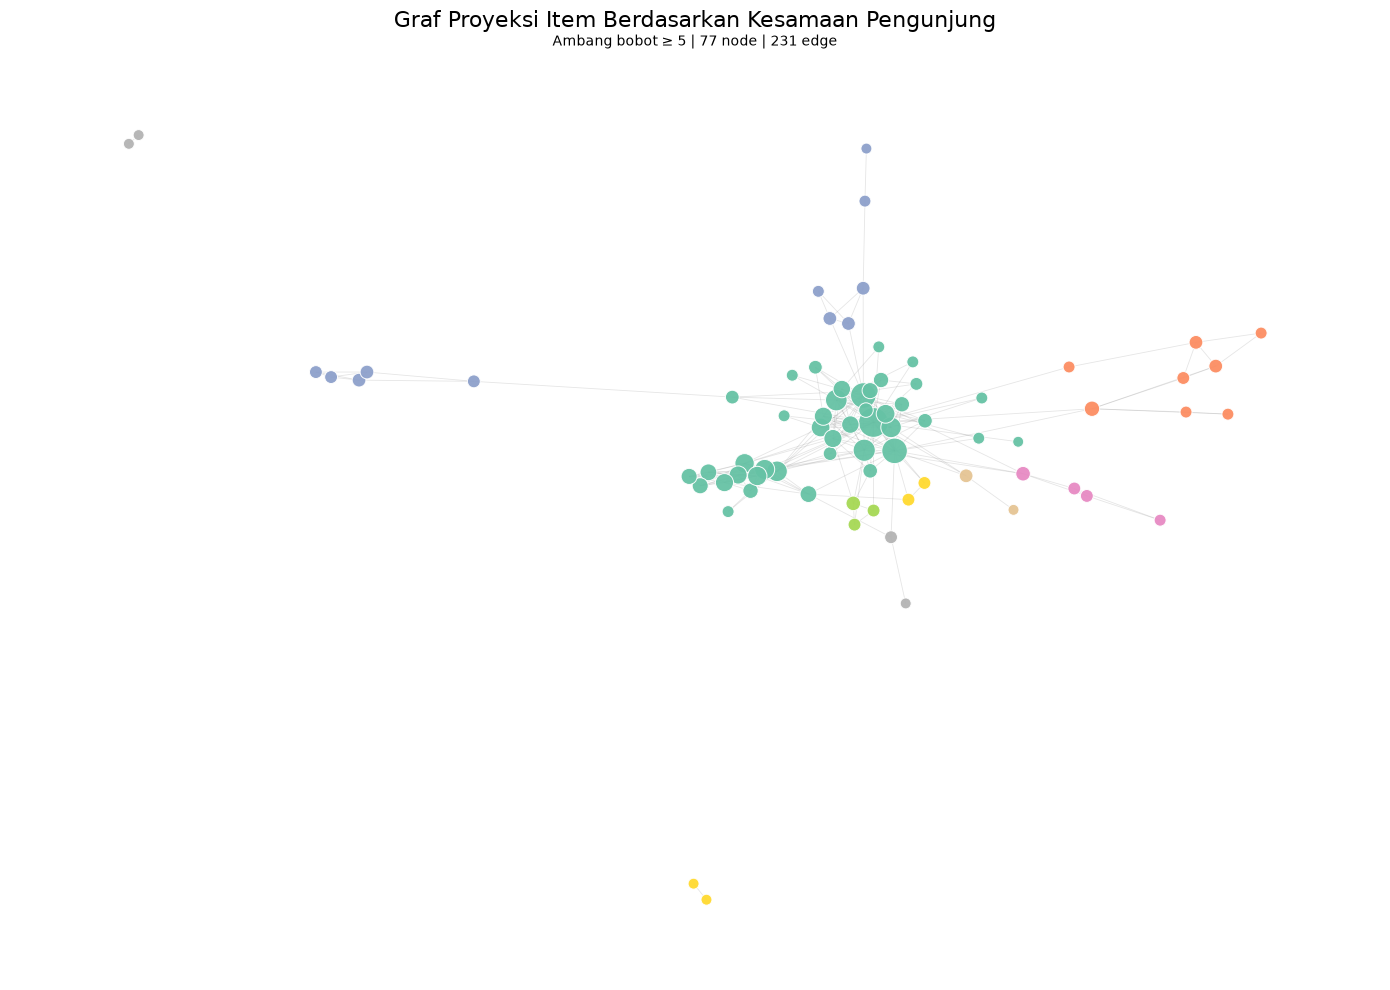

In [82]:
batas_bobot_item = 5

G_item_visual = nx.Graph()
G_item_visual.add_nodes_from(G_proyeksi_item.nodes())

G_item_visual.add_edges_from(
    (u, v, data.copy())
    for u, v, data in G_proyeksi_item.edges(data=True)
    if data["weight"] >= batas_bobot_item
)

G_item_visual.remove_nodes_from(
    list(nx.isolates(G_item_visual))
)

print("Node yang ditampilkan:", G_item_visual.number_of_nodes())
print("Edge yang ditampilkan:", G_item_visual.number_of_edges())

if G_item_visual.number_of_nodes() > 0:
    degree_item = dict(G_item_visual.degree())
    komunitas = list(
        nx.community.greedy_modularity_communities(
            G_item_visual,
            weight="weight"
        )
    )

    warna_node = {}
    for nomor, anggota in enumerate(komunitas):
        for node in anggota:
            warna_node[node] = nomor
    pos = nx.spring_layout(
        G_item_visual,
        seed=42,
        k=0.7,
        iterations=150,
        weight="weight"
    )

    ukuran_node = [
        50 + degree_item[node] * 12
        for node in G_item_visual.nodes()
    ]

    warna = [
        warna_node[node]
        for node in G_item_visual.nodes()
    ]

    fig, ax = plt.subplots(figsize=(14, 10))

    nx.draw_networkx_edges(
        G_item_visual,
        pos,
        ax=ax,
        edge_color="gray",
        alpha=0.20,
        width=0.6
    )

    nx.draw_networkx_nodes(
        G_item_visual,
        pos,
        ax=ax,
        node_size=ukuran_node,
        node_color=warna,
        cmap=plt.cm.Set2,
        edgecolors="white",
        linewidths=0.7,
        alpha=0.95
    )

    ax.set_title(
        "Graf Proyeksi Item Berdasarkan Kesamaan Pengunjung",
        fontsize=16,
        pad=20
    )
    ax.text(
        0.5, 1.01,
        f"Ambang bobot ≥ {batas_bobot_item} | "
        f"{G_item_visual.number_of_nodes()} node | "
        f"{G_item_visual.number_of_edges()} edge",
        transform=ax.transAxes,
        ha="center",
        fontsize=10
    )

    ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print(
        "Tidak ada edge yang memenuhi ambang bobot. "
        "Coba turunkan batas_bobot_item menjadi 3."
    )

Graf Proyeksi Item Berdasarkan Kesamaan Pengunjung dengan ambang batas bobot >5, yang terdiri dari 77 node dan 231 edge. Ini menunjukkan klaster produk yang sering diakses atau dibeli oleh kelompok pengunjung yang serupa, di mana warna-warna yang berbeda merepresentasikan pengelompokan komunitas produk (community detection) di dalam sistem

## **Menghitung cosine similarity antar-Visitor**

In [50]:
from sklearn.metrics.pairwise import cosine_similarity

reference_idx = 0
reference_visitor = list(visitor_map.keys())[reference_idx]

similarities = cosine_similarity(
    visitor_vsm[reference_idx],
    visitor_vsm
).ravel()

top_indices = np.argsort(similarities)[::-1]
top_indices = [
    idx for idx in top_indices
    if idx != reference_idx
][:5]

visitor_ids_ordered = list(visitor_map.keys())

print("Visitor referensi:", reference_visitor)
print("\nTop 5 Visitor paling mirip:")

for rank, idx in enumerate(top_indices, start=1):
    print(
        f"{rank}. Visitor {visitor_ids_ordered[idx]} "
        f"| Cosine similarity: {similarities[idx]:.4f}"
    )

Visitor referensi: 257597

Top 5 Visitor paling mirip:
1. Visitor 1220596 | Cosine similarity: 1.0000
2. Visitor 306807 | Cosine similarity: 1.0000
3. Visitor 719125 | Cosine similarity: 1.0000
4. Visitor 981382 | Cosine similarity: 0.5000
5. Visitor 1321933 | Cosine similarity: 0.4472


## **Menghitung cosine similarity antar-Item**

In [51]:
from sklearn.metrics.pairwise import cosine_similarity

item_ids_ordered = list(item_map.keys())

reference_item_idx = 0
reference_item = item_ids_ordered[reference_item_idx]

item_similarities = cosine_similarity(
    item_vsm[reference_item_idx],
    item_vsm
).ravel()

top_item_indices = np.argsort(item_similarities)[::-1]
top_item_indices = [
    idx for idx in top_item_indices
    if idx != reference_item_idx
][:5]

print("Item referensi:", reference_item)
print("\nTop 5 Item paling mirip:")

for rank, idx in enumerate(top_item_indices, start=1):
    print(
        f"{rank}. Item {item_ids_ordered[idx]} "
        f"| Cosine similarity: {item_similarities[idx]:.4f}"
    )

Item referensi: 355908

Top 5 Item paling mirip:
1. Item 97139 | Cosine similarity: 0.3059
2. Item 375752 | Cosine similarity: 0.2673
3. Item 175694 | Cosine similarity: 0.2673
4. Item 179185 | Cosine similarity: 0.2673
5. Item 224595 | Cosine similarity: 0.2673


## **Membandingkan karakteristik VSM**

In [54]:
print("PERBANDINGAN VSM")

print("\nVSM Visitor")
print("Shape:", visitor_vsm.shape)
print("Jumlah nilai non-zero:", visitor_vsm.nnz)
print("Jumlah elemen:", visitor_vsm.shape[0] * visitor_vsm.shape[1])

print("\nVSM Item")
print("Shape:", item_vsm.shape)
print("Jumlah nilai non-zero:", item_vsm.nnz)
print("Jumlah elemen:", item_vsm.shape[0] * item_vsm.shape[1])

visitor_density = visitor_vsm.nnz / (
    visitor_vsm.shape[0] * visitor_vsm.shape[1]
)
item_density = item_vsm.nnz / (
    item_vsm.shape[0] * item_vsm.shape[1]
)

print("\nKerapatan matriks")
print(f"Visitor VSM: {visitor_density:.8%}")
print(f"Item VSM: {item_density:.8%}")

PERBANDINGAN VSM

VSM Visitor
Shape: (363786, 125585)
Jumlah nilai non-zero: 546557
Jumlah elemen: 45686064810

VSM Item
Shape: (125585, 363786)
Jumlah nilai non-zero: 546557
Jumlah elemen: 45686064810

Kerapatan matriks
Visitor VSM: 0.00119633%
Item VSM: 0.00119633%


Dari hasil VSM, matriks Visitor memiliki ukuran 363.786 × 125.585, sedangkan matriks Item memiliki ukuran 125.585 × 363.786. VSM Visitor digunakan untuk melihat kemiripan pola interaksi antarvisitor berdasarkan item yang diakses, sedangkan VSM Item digunakan untuk melihat kemiripan antaritem berdasarkan visitor yang berinteraksi dengannya. Kedua matriks memiliki 546.557 elemen tidak nol dengan tingkat kepadatan hanya 0,00119633%, sehingga sebagian besar elemennya bernilai nol dan cocok disimpan menggunakan format sparse matrix agar lebih hemat memori. Dari segi penerapan, VSM Visitor lebih sesuai untuk rekomendasi berdasarkan kemiripan perilaku pengguna, sedangkan VSM Item lebih sesuai untuk rekomendasi item yang memiliki pola interaksi serupa. Namun, efisiensi waktu pemrosesan keduanya perlu diuji terlebih dahulu sebelum menentukan mana yang lebih efisien.

## **Perbandingan Proyeksi Visitor dan Item**

In [84]:
jumlah_node_visitor = G_proyeksi_visitor.number_of_nodes()
jumlah_edge_visitor = G_proyeksi_visitor.number_of_edges()

jumlah_node_item = G_proyeksi_item.number_of_nodes()
jumlah_edge_item = G_proyeksi_item.number_of_edges()

density_visitor = nx.density(G_proyeksi_visitor)
density_item = nx.density(G_proyeksi_item)

df_perbandingan = pd.DataFrame({
    "Karakteristik": [
        "Jumlah node",
        "Jumlah edge",
        "Density"
    ],
    "Proyeksi Visitor": [
        jumlah_node_visitor,
        jumlah_edge_visitor,
        density_visitor
    ],
    "Proyeksi Item": [
        jumlah_node_item,
        jumlah_edge_item,
        density_item
    ]
})

display(df_perbandingan)

,Karakteristik,Proyeksi Visitor,Proyeksi Item
0,Jumlah node,100.000000,497.000000
1,Jumlah edge,2922.000000,2220.000000
2,Density,0.590303,0.018011


Berdasarkan hasil perbandingan, proyeksi Visitor memiliki 100 node dan 2.922 edge dengan nilai density sebesar 0,590303, sedangkan proyeksi Item memiliki 497 node dan 2.220 edge dengan nilai density sebesar 0,018011. Hal ini menunjukkan bahwa hubungan antar-Visitor pada graf sampel lebih rapat dibandingkan hubungan antar-Item. Proyeksi Visitor lebih sesuai untuk mengamati kemiripan pola interaksi antar pengguna, sedangkan proyeksi Item dapat digunakan untuk melihat keterkaitan antar barang berdasarkan kesamaan pengunjung. Namun, efisiensi komputasi kedua proyeksi tetap perlu dinilai berdasarkan waktu pemrosesan, dan hasil perbandingan ini perlu mempertimbangkan bahwa kedua graf menggunakan sampel yang berbeda.

## **Membandingkan efisiensi waktu**

In [85]:
import time
from sklearn.metrics.pairwise import cosine_similarity

start = time.perf_counter()

visitor_sim_test = cosine_similarity(
    visitor_vsm[0],
    visitor_vsm
).ravel()

visitor_time = time.perf_counter() - start

start = time.perf_counter()

item_sim_test = cosine_similarity(
    item_vsm[0],
    item_vsm
).ravel()

item_time = time.perf_counter() - start

print(f"Waktu similarity Visitor: {visitor_time:.4f} detik")
print(f"Waktu similarity Item: {item_time:.4f} detik")

Waktu similarity Visitor: 0.0621 detik
Waktu similarity Item: 0.0468 detik


Berdasarkan pengujian efisiensi waktu, perhitungan similarity pada VSM Visitor membutuhkan waktu 0,0228 detik, sedangkan VSM Item membutuhkan waktu 0,0238 detik. Hasil tersebut menunjukkan bahwa VSM Visitor sedikit lebih cepat dengan selisih waktu 0,001 detik dibandingkan VSM Item. Dengan demikian, VSM Visitor lebih efisien dari segi waktu pemrosesan pada pengujian ini, meskipun perbedaannya relatif kecil. Namun, hasil tersebut berlaku untuk pengujian yang dilakukan dan dapat berubah bergantung pada data serta kondisi pemrosesan.

## **Query Cypher untuk 5 Similarity Tertinggi**

In [ ]:
MATCH (acuan:Visitor {id: 257597})
-[r:SIMILAR_TO]->(mirip:Visitor)
RETURN
    acuan.id AS visitor_acuan,
    mirip.id AS visitor_mirip,
    r.similarity AS similarity
ORDER BY similarity DESC
LIMIT 5;

## **Sebelum Perhitungan Similarity**

In [ ]:
MATCH (v:Visitor {id: 257597})-[r:INTERACTED]->(i:Item)
RETURN v, r, i;

## **Sesudah Perhitungan Similarity**

In [ ]:
MATCH (acuan:Visitor {id: 257597})-[r:SIMILAR_TO]->(mirip:Visitor)
RETURN acuan, r, mirip;

## **2.2 Analytics**

## **Memilih user secara acak**

In [60]:
daftar_visitor = np.sort(df_p1["visitorid"].dropna().unique())

rng = np.random.RandomState(42)
visitor_terpilih = rng.choice(daftar_visitor)

print("Visitor terpilih:", visitor_terpilih)

Visitor terpilih: 471463


## **Menentukan item yang sudah pernah diakses user**

In [64]:
df_p2 = pd.read_csv("../data/events_P2_testing.csv")
riwayat_p1 = df_p1[
    df_p1["visitorid"] == visitor_terpilih
]

riwayat_p2 = df_p2[
    df_p2["visitorid"] == visitor_terpilih
]

print("Jumlah interaksi P1:", len(riwayat_p1))
print("Jumlah item unik P1:", riwayat_p1["itemid"].nunique())
print("Jumlah interaksi P2:", len(riwayat_p2))
print("Jumlah item unik P2:", riwayat_p2["itemid"].nunique())

print("\nRiwayat interaksi P1:")
display(riwayat_p1[["visitorid", "itemid", "event"]].head(10))

print("\nRiwayat interaksi P2:")
display(riwayat_p2[["visitorid", "itemid", "event"]].head(10))

Jumlah interaksi P1: 4
Jumlah item unik P1: 4
Jumlah interaksi P2: 0
Jumlah item unik P2: 0

Riwayat interaksi P1:


,visitorid,itemid,event
284801,471463,87858,view
286925,471463,277368,view
293708,471463,153120,view
295878,471463,91357,view



Riwayat interaksi P2:


,visitorid,itemid,event


## **Memilih user yang muncul pada P1 dan P2**

In [65]:
visitor_p1 = set(df_p1["visitorid"].dropna().unique())
visitor_p2 = set(df_p2["visitorid"].dropna().unique())

kandidat_visitor = np.array(
    sorted(visitor_p1.intersection(visitor_p2))
)

print("Jumlah kandidat Visitor:", len(kandidat_visitor))

rng = np.random.RandomState(42)
visitor_terpilih = rng.choice(kandidat_visitor)

print("Visitor terpilih:", visitor_terpilih)

Jumlah kandidat Visitor: 7397
Visitor terpilih: 1383723


## **Memeriksa riwayat Visitor 1383723**

In [66]:
riwayat_p1 = df_p1[df_p1["visitorid"] == visitor_terpilih]
riwayat_p2 = df_p2[df_p2["visitorid"] == visitor_terpilih]

print("Jumlah interaksi P1:", len(riwayat_p1))
print("Jumlah item unik P1:", riwayat_p1["itemid"].nunique())
print("Jumlah interaksi P2:", len(riwayat_p2))
print("Jumlah item unik P2:", riwayat_p2["itemid"].nunique())

print("\nRiwayat P1:")
display(riwayat_p1[["visitorid", "itemid", "event"]].head(10))

print("\nRiwayat P2:")
display(riwayat_p2[["visitorid", "itemid", "event"]].head(10))

Jumlah interaksi P1: 43
Jumlah item unik P1: 3
Jumlah interaksi P2: 11
Jumlah item unik P2: 1

Riwayat P1:


,visitorid,itemid,event
10251,1383723,65268,view
31985,1383723,65268,view
58486,1383723,65268,view
78310,1383723,65268,view
286479,1383723,325077,view
312915,1383723,325077,view
316226,1383723,325077,view
325167,1383723,325077,view
356342,1383723,325077,view
368442,1383723,325077,view



Riwayat P2:


,visitorid,itemid,event
3853,1383723,65268,view
7987,1383723,65268,view
29248,1383723,65268,view
47281,1383723,65268,view
51689,1383723,65268,view
76114,1383723,65268,view
88815,1383723,65268,view
124775,1383723,65268,view
139369,1383723,65268,view
151858,1383723,65268,view


## **Menentukan user untuk evaluasi**

In [67]:
item_p1_per_visitor = (
    df_p1.groupby("visitorid")["itemid"]
    .apply(set)
    .to_dict()
)

kandidat_evaluasi = []

for visitor_id, group in df_p2.groupby("visitorid"):
    if visitor_id not in item_p1_per_visitor:
        continue

    item_training = item_p1_per_visitor[visitor_id]
    item_testing = set(group["itemid"].dropna())

    if item_testing - item_training:
        kandidat_evaluasi.append(visitor_id)

kandidat_evaluasi = np.array(sorted(kandidat_evaluasi))

print("Jumlah kandidat evaluasi:", len(kandidat_evaluasi))

rng = np.random.RandomState(42)
visitor_terpilih = rng.choice(kandidat_evaluasi)

print("Visitor terpilih:", visitor_terpilih)

item_training = item_p1_per_visitor[visitor_terpilih]
item_testing = set(
    df_p2.loc[
        df_p2["visitorid"] == visitor_terpilih, "itemid"
    ].dropna()
)

item_relevan = item_testing - item_training

print("Item unik P1:", len(item_training))
print("Item unik P2:", len(item_testing))
print("Item relevan untuk evaluasi:", sorted(item_relevan))

Jumlah kandidat evaluasi: 5536
Visitor terpilih: 222553
Item unik P1: 2
Item unik P2: 1
Item relevan untuk evaluasi: [13219]


## **Mencari lima tetangga terdekat menggunakan KNN**

In [71]:
from sklearn.preprocessing import normalize
from sklearn.neighbors import NearestNeighbors
import numpy as np
import pandas as pd

X = normalize(visitor_item_matrix, norm="l2", axis=1)

visitor_ids = np.array(list(visitor_map.keys()))

idx_target = visitor_map[visitor_terpilih]

knn_model = NearestNeighbors(
    n_neighbors=6,
    metric="cosine",
    algorithm="brute"
)
knn_model.fit(X)

jarak, indeks = knn_model.kneighbors(X[idx_target])

hasil_knn = []

for d, idx in zip(jarak[0], indeks[0]):
    visitor_id = visitor_ids[idx]

    if visitor_id != visitor_terpilih:
        hasil_knn.append({
            "visitor_id": visitor_id,
            "similarity": 1 - d
        })

    if len(hasil_knn) == 5:
        break

df_knn = pd.DataFrame(hasil_knn)
display(df_knn)

,visitor_id,similarity
0,437308,0.894427
1,124821,0.894427
2,333025,0.774597
3,765777,0.632456
4,823982,0.565685


## **Rekomendasi barang**

In [72]:
interaksi_unik = df_p1[["visitorid", "itemid"]].drop_duplicates()

item_pernah_dilihat = set(
    df_p1.loc[
        df_p1["visitorid"] == visitor_terpilih, "itemid"
    ].dropna()
)

skor_item = {}

for _, tetangga in df_knn.iterrows():
    id_tetangga = tetangga["visitor_id"]
    similarity = tetangga["similarity"]

    item_tetangga = set(
        interaksi_unik.loc[
            interaksi_unik["visitorid"] == id_tetangga, "itemid"
        ].dropna()
    )

    for item in item_tetangga:
        if item not in item_pernah_dilihat:
            skor_item[item] = skor_item.get(item, 0) + similarity

peringkat_item = sorted(
    skor_item.items(),
    key=lambda x: (-x[1], x[0])
)

df_rekomendasi = pd.DataFrame(
    peringkat_item[:5],
    columns=["item_id", "skor_rekomendasi"]
)

print("User target:", visitor_terpilih)
print("5 rekomendasi teratas:")
display(df_rekomendasi)

print("3 item rekomendasi:")
display(df_rekomendasi.head(3))

User target: 222553
5 rekomendasi teratas:


,item_id,skor_rekomendasi
0,141572,0.774597
1,46232,0.632456
2,191049,0.565685
3,229598,0.565685
4,463635,0.565685


3 item rekomendasi:


,item_id,skor_rekomendasi
0,141572,0.774597
1,46232,0.632456
2,191049,0.565685


Sistem rekomendasi mengumpulkan barang yang pernah diakses oleh lima tetangga terdekat, kemudian memberikan skor berdasarkan penjumlahan nilai similarity tetangga yang berinteraksi dengan barang tersebut. Barang yang sudah pernah diakses oleh Visitor 222553 pada periode training dikeluarkan dari kandidat rekomendasi. Berdasarkan hasil pengurutan skor, Item 141572 menempati peringkat pertama dengan skor 0,774597, diikuti Item 46232 dengan skor 0,632456 dan Item 191049 dengan skor 0,565685. Ketiga item tersebut menjadi rekomendasi utama yang dihasilkan sistem untuk pengunjung target.

## **Menghitung Hit@5 dan NDCG@5**

In [111]:
interaksi_unik_p1 = (
    df_p1[["visitorid", "itemid"]]
    .dropna()
    .drop_duplicates()
)

popularitas_item = (
    interaksi_unik_p1.groupby("itemid")["visitorid"]
    .nunique()
    .sort_values(ascending=False)
)

hasil_evaluasi_hybrid = []

for visitor_id in kandidat_evaluasi[:100]:
    visitor_id = int(visitor_id)

    if visitor_id not in visitor_map_knn:
        continue

    item_training = set(
        interaksi_unik_p1.loc[
            interaksi_unik_p1["visitorid"] == visitor_id,
            "itemid"
        ]
    )

    idx_target = visitor_map_knn[visitor_id]
    jarak, indeks = model_knn.kneighbors(
        X_normalisasi[idx_target]
    )

    tetangga = []
    for d, idx in zip(jarak[0], indeks[0]):
        id_tetangga = int(visitor_ids[idx])

        if id_tetangga == visitor_id:
            continue

        tetangga.append((id_tetangga, float(1 - d)))

        if len(tetangga) == 5:
            break

    skor = {}

    for id_tetangga, similarity in tetangga:
        item_tetangga = set(
            interaksi_unik_p1.loc[
                interaksi_unik_p1["visitorid"] == id_tetangga,
                "itemid"
            ]
        )

        for item in item_tetangga - item_training:
            skor[item] = skor.get(item, 0) + similarity

    rekomendasi_knn = [
        item for item, _ in sorted(
            skor.items(), key=lambda x: (-x[1], x[0])
        )[:5]
    ]

    rekomendasi = list(rekomendasi_knn)

    for item in popularitas_item.index:
        if len(rekomendasi) >= 5:
            break

        if item not in item_training and item not in rekomendasi:
            rekomendasi.append(item)

    item_testing = set(
        df_p2.loc[
            df_p2["visitorid"] == visitor_id,
            "itemid"
        ].dropna()
    )

    item_relevan = item_testing - item_training

    hit5 = int(any(
        item in item_relevan for item in rekomendasi[:5]
    ))

    dcg5 = sum(
        1 / np.log2(posisi + 1)
        for posisi, item in enumerate(rekomendasi[:5], start=1)
        if item in item_relevan
    )

    idcg5 = sum(
        1 / np.log2(posisi + 1)
        for posisi in range(
            1, min(len(item_relevan), 5) + 1
        )
    )

    ndcg5 = dcg5 / idcg5 if idcg5 > 0 else 0.0

    hasil_evaluasi_hybrid.append({
        "visitor_id": visitor_id,
        "jumlah_item_relevan": len(item_relevan),
        "jumlah_rekomendasi": len(rekomendasi),
        "Hit@5": hit5,
        "NDCG@5": ndcg5
    })

df_evaluasi_hybrid = pd.DataFrame(hasil_evaluasi_hybrid)

display(df_evaluasi_hybrid.head(10))

print("Jumlah Visitor dievaluasi:", len(df_evaluasi_hybrid))
print("Rata-rata Hit@5:",
      round(df_evaluasi_hybrid["Hit@5"].mean(), 4))
print("Rata-rata NDCG@5:",
      round(df_evaluasi_hybrid["NDCG@5"].mean(), 4))

,visitor_id,jumlah_item_relevan,jumlah_rekomendasi,Hit@5,NDCG@5
0,74,1,5,0,0.0
1,197,1,5,0,0.0
2,586,1,5,0,0.0
3,1136,1,5,0,0.0
4,1172,1,5,0,0.0
5,1430,3,5,0,0.0
6,1470,1,5,0,0.0
7,1647,1,5,0,0.0
8,1879,2,5,0,0.0
9,2019,2,5,0,0.0


Jumlah Visitor dievaluasi: 100
Rata-rata Hit@5: 0.01
Rata-rata NDCG@5: 0.0043


Berdasarkan hasil evaluasi terhadap 100 Visitor, metode hybrid KNN dengan \(k=5\) yang dikombinasikan dengan popularitas Item berhasil menghasilkan rekomendasi untuk seluruh Visitor yang diuji. Nilai rata-rata Hit@5 sebesar 0,01 menunjukkan bahwa hanya sekitar 1% Visitor yang mendapatkan setidaknya satu Item relevan dalam lima rekomendasi teratas. Sementara itu, nilai rata-rata NDCG@5 sebesar 0,0043 menunjukkan bahwa kualitas dan urutan rekomendasi yang dihasilkan masih rendah. Meskipun pendekatan fallback popularitas berhasil mengatasi masalah tidak tersedianya kandidat rekomendasi.